# Assignment 2: Estimation Theory and Bayes Techniques

*Authors:* Eric Volkmann / Klemens Hauzenberg / Bertalan Toppantó / Markus Holzleitner

*Copyright statement:* This  material,  no  matter  whether  in  printed  or  electronic  form,  may  be  used  for  personal  and non-commercial educational use only.  Any reproduction of this manuscript, no matter whether as a whole or in parts, no matter whether in printed or in electronic form, requires explicit prior acceptance of the authors.

## Organisation and notation

Derivation tasks are answered in the markdown cells marked *YOUR SOLUTION HERE*, programming tasks in the corresponding code cells.

Notation used throughout the assignment:

* **Data:** $z_1, \dots, z_l \overset{\text{i.i.d.}}{\sim} p(z; w)$, collected in $\mathbf Z = (z_1, \dots, z_l)$; $l$ is the sample size. (In the code cells the sample size $l$ is called `n`.)
* **Estimators:** an estimator $\hat w = \hat w(\mathbf Z)$ has bias $b(\hat w) = \mathbb E[\hat w] - w$, variance $\mathrm{var}(\hat w) = \mathbb E\big[(\hat w - \mathbb E[\hat w])^2\big]$ and mean squared error $\mathrm{mse}(\hat w) = \mathbb E\big[(\hat w - w)^2\big] = \mathrm{var}(\hat w) + b^2(\hat w)$. All expectations are with respect to $\mathbf Z \sim p(\cdot\,; w)^l$.
* **Sample mean:** $\hat\mu = \frac1l \sum_{i=1}^l z_i$.
* **Likelihood:** $\mathcal L(\mathbf Z; w) = \prod_{i=1}^l p(z_i; w)$; maximum likelihood estimator $\hat w_{\mathrm{MLE}} \in \arg\max_w \mathcal L(\mathbf Z; w)$.
* **Score and Fisher information** of a *single* observation (scalar parameter): $s(z; w) = \frac{\partial \log p(z; w)}{\partial w}$ and $I_F(w) = \mathbb E\big[s(z;w)^2\big]$; under the usual regularity conditions (see Exercise 3), $I_F(w) = -\mathbb E\Big[\frac{\partial^2 \log p(z;w)}{\partial w^2}\Big]$. (For vector-valued $w$ this is the matrix $\mathbb E[s\,s^\top]$.) We write $I_F^{(l)}(w)$ for the Fisher information of the whole sample $\mathbf Z$; Exercise 3a shows $I_F^{(l)}(w) = l \cdot I_F(w)$.
* **Cramér–Rao lower bound (CRLB)** for a scalar parameter: $\mathrm{var}(\hat w) \ge 1 / I_F^{(l)}(w)$ for every *unbiased* estimator $\hat w$ based on $\mathbf Z$; an unbiased estimator attaining the bound is called *efficient*.
* $\log$ denotes the natural logarithm.

## Warmup: Central Limit Theorem

### Exercise 1: Central Limit Theorem Simulation (2 pts)

The central limit theorem (CLT) states: if $z_1, \dots, z_l$ are i.i.d. with $\mathbb E[z_i] = \mu$ and $\mathrm{var}(z_i) = \sigma^2 < \infty$, then the sample mean $\hat\mu = \frac1l\sum_{i=1}^l z_i$ satisfies
\begin{equation*}
    \sqrt{l}\,(\hat\mu - \mu) \;\xrightarrow{d}\; \mathcal N(0, \sigma^2) \qquad (l \to \infty),
\end{equation*}
regardless of the distribution of the $z_i$. Equivalently, the standardized sample mean ($z$-score)
\begin{equation*}
    \frac{\hat\mu - \mu}{\sigma / \sqrt{l}}
\end{equation*}
is approximately standard normal for large $l$. This is why estimators such as $\hat\mu$ are treated as approximately Gaussian in practice — but only for "sufficiently large" $l$. The goal of this exercise is to build intuition for the **pre-asymptotic** behaviour, i.e. how good the normal approximation is for finite sample sizes, which is all we ever have in practice.

#### Helper functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

rng = np.random.default_rng(0)


def simulate_sample_means(sampler, sample_sizes, monte_carlo_sims=2000):
    """
    Simulates the distribution of the sample mean for a given distribution.

    Args:
        sampler: a function `sampler(n)` that returns n i.i.d. samples of the distribution.
        sample_sizes: list of sample sizes n (= l in the notation of the lecture).
        monte_carlo_sims: number of Monte Carlo repetitions per sample size.

    Returns:
        dict mapping each sample size to a numpy array of `monte_carlo_sims` sample means.
    """
    return {n: np.array([np.mean(sampler(n)) for _ in range(monte_carlo_sims)]) for n in sample_sizes}


def z_scores(sample_means, mean, var):
    """Standardizes the sample means with the true mean and variance of the distribution."""
    return {n: (means - mean) / np.sqrt(var / n) for n, means in sample_means.items()}


def plot_results(z, title):
    """QQ-plots and density plots of the z-scores against the standard normal distribution."""
    sample_sizes = list(z.keys())
    fig, axes = plt.subplots(1, len(sample_sizes), figsize=(4 * len(sample_sizes), 4))
    for ax, n in zip(axes, sample_sizes):
        stats.probplot(z[n], dist="norm", plot=ax)
        ax.set_title(f"QQ-plot (n={n})")
    fig.suptitle(f"{title} - QQ-plots", fontsize=14)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, len(sample_sizes), figsize=(4 * len(sample_sizes), 4))
    x = np.linspace(-4, 6, 500)
    edges = np.linspace(-4, 6, 51)
    for ax, n in zip(axes, sample_sizes):
        # histogram normalized to a density on the full data (mass outside [-4, 6] is not shown)
        weights = np.full(z[n].shape, 1.0 / (len(z[n]) * (edges[1] - edges[0])))
        ax.hist(z[n], bins=edges, weights=weights, alpha=0.6, label="z-scores")
        ax.plot(x, stats.norm.pdf(x), "r-", lw=2, label="N(0, 1)")
        ax.set_title(f"Density (n={n})")
        ax.legend()
    fig.suptitle(f"{title} - Density plots", fontsize=14)
    plt.tight_layout()
    plt.show()


def print_moments(z):
    """Prints the first four moments of the z-scores (for N(0, 1): 0, 1, 0, 0)."""
    print("n\tMean\tVariance\tSkewness\tKurtosis")
    for n, zn in z.items():
        print(f"{n}\t{np.mean(zn):.3f}\t{np.var(zn):.3f}\t\t{stats.skew(zn):.3f}\t\t{stats.kurtosis(zn):.3f}")


sample_sizes = [2, 5, 20, 100, 1000]

Use the helper functions above to simulate the CLT for the sample sizes in `sample_sizes` and the two distributions below: simulate the sample means, standardize them with the true mean and variance of the distribution ($z$-scores), make the QQ-plots and density plots, and print the moments of the $z$-scores.

*Hint: use the samplers of the generator `rng`, e.g. `rng.exponential`, `rng.pareto` (see `numpy.random.Generator`).*

#### 1a) Simulation (1 pt)

##### Exponential distribution

The exponential distribution with rate $\lambda = 1$, i.e. $p(z) = e^{-z}$ for $z \ge 0$, with $\mathbb E[z] = 1$ and $\mathrm{var}(z) = 1$. (This distribution accompanies us through the rest of the assignment.)

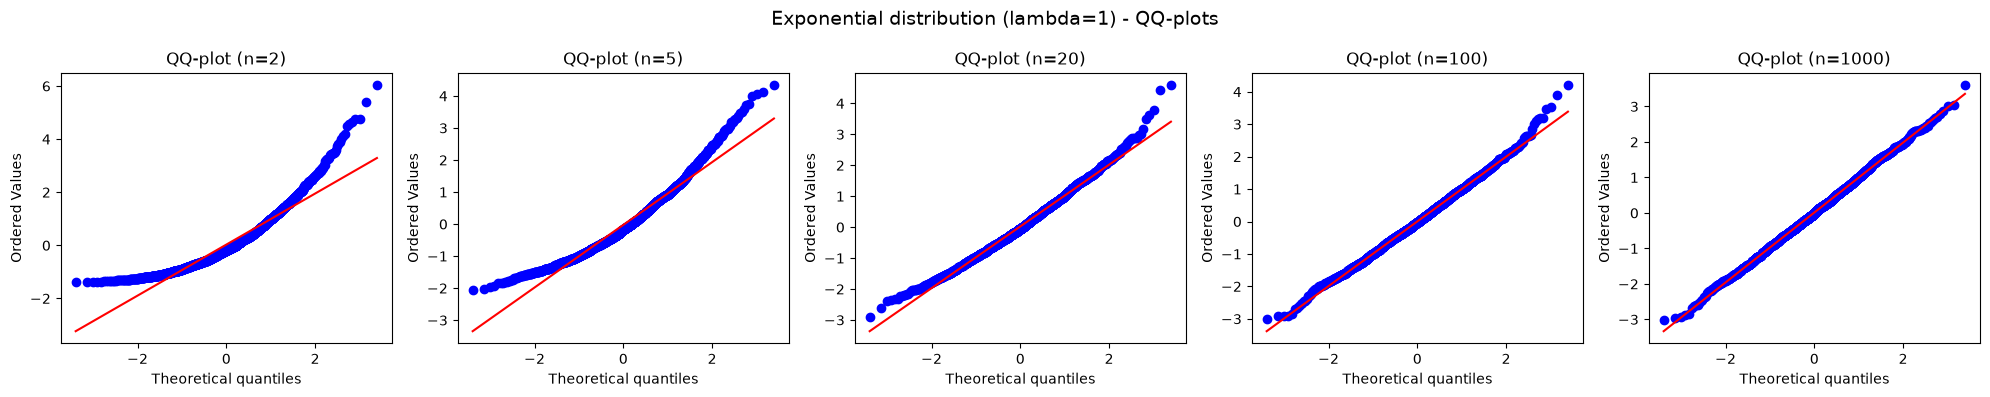

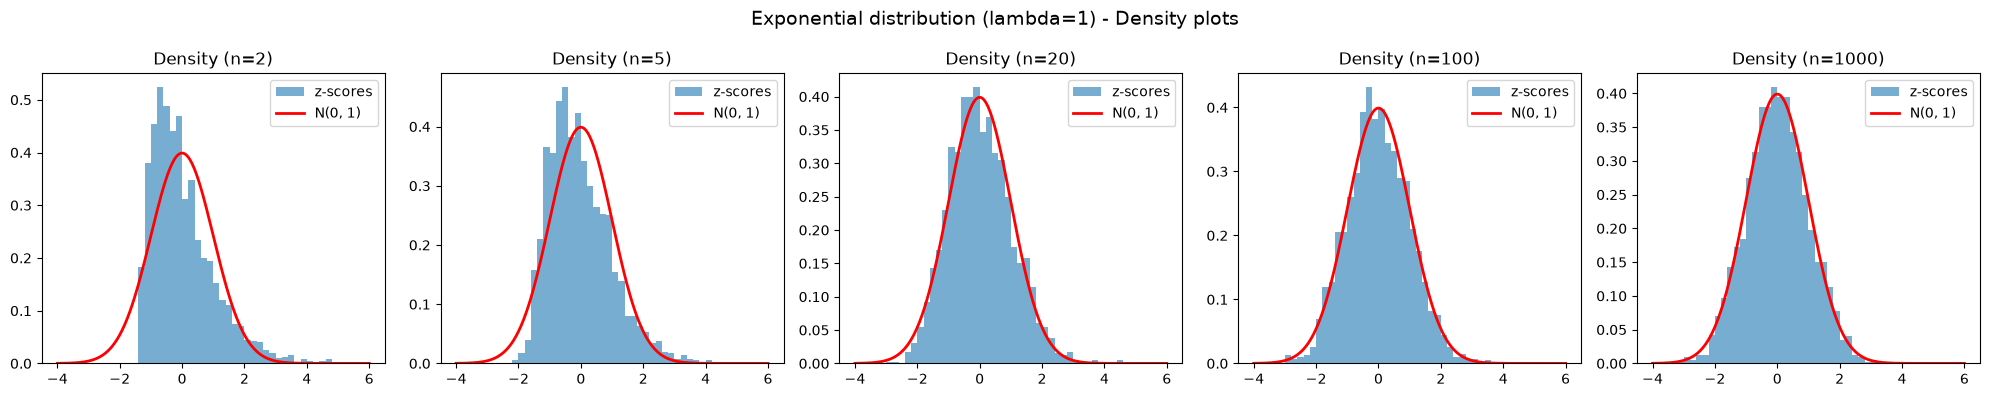

n	Mean	Variance	Skewness	Kurtosis
2	0.028	1.020		1.361		2.654
5	-0.024	0.999		0.867		0.878
20	0.024	1.002		0.381		0.264
100	0.003	0.995		0.180		0.172
1000	0.012	0.969		0.059		-0.085


In [ ]:
########## YOUR SOLUTION HERE ##########

## Normal distribution (mean=1, var=1)
exp_mean = 1.0
exp_var = 1.0

# Simulate sample means for the exponential distribution (lambda=1)
exp_sample_means = simulate_sample_means(
    sampler=lambda n: rng.exponential(scale=1.0, size=n),
    sample_sizes=sample_sizes,
    monte_carlo_sims=2000,
)

# Compute z-scores for the exponential distribution
exp_z = z_scores(
    exp_sample_means,
    mean=exp_mean,
    var=exp_var,
)

plot_results(exp_z, "Exponential distribution (lambda=1)")
print_moments(exp_z)

### Interpretation

As the sample size increases, the standardized sample means approach a standard normal distribution. For n = 2 and 5, the distributions remain visibly right-skewed. At n = 20, the approximation is reasonable in the center, although deviations remain in the tails. For n = 100 and 1000, the histograms closely match the standard normal curve, and the QQ-plots are approximately linear. This illustrates the central limit theorem.

##### Pareto distribution

The (classical) Pareto distribution with scale $x_m = 1$ and tail index $\alpha = 2.1$, i.e. $p(z) = \alpha z^{-\alpha - 1}$ for $z \ge 1$, with
\begin{equation*}
    \mathbb E[z] = \frac{\alpha}{\alpha - 1}, \qquad \mathrm{var}(z) = \frac{\alpha}{(\alpha - 1)^2 (\alpha - 2)},
\end{equation*}
which is finite since $\alpha > 2$, so the CLT applies. Samples can be generated with `rng.pareto(alpha, n) + 1` (NumPy's `pareto` is the Lomax distribution, i.e. the classical Pareto distribution shifted by $-1$).

https://en.wikipedia.org/wiki/Pareto_distribution

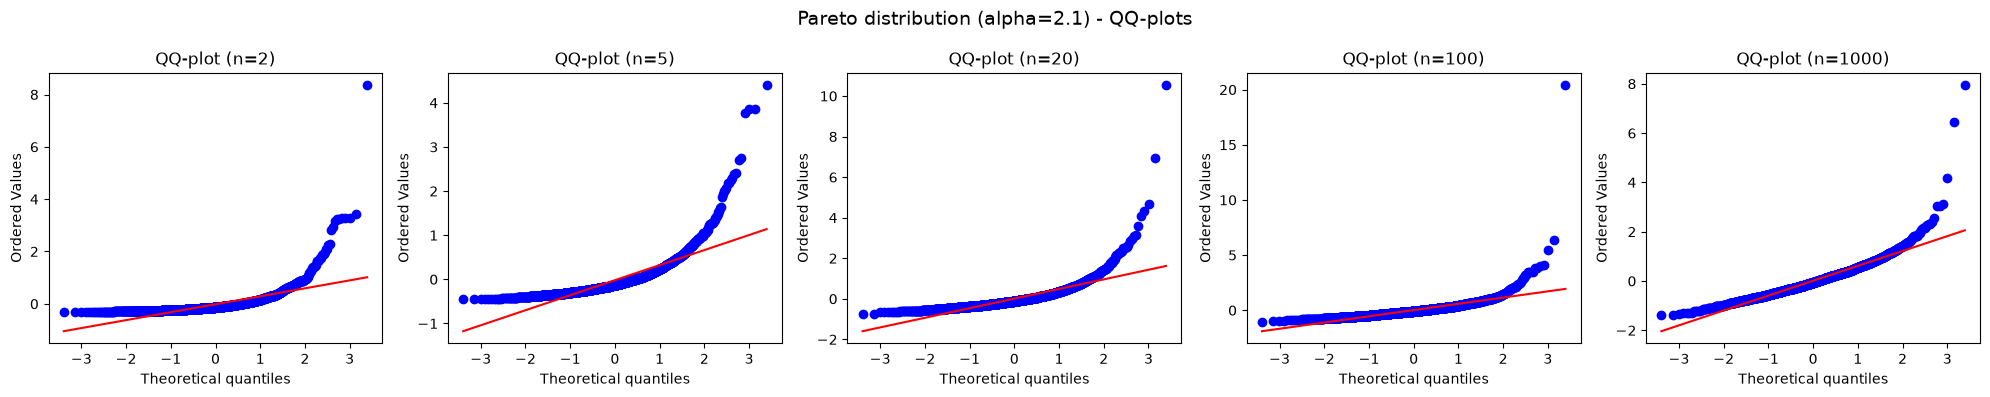

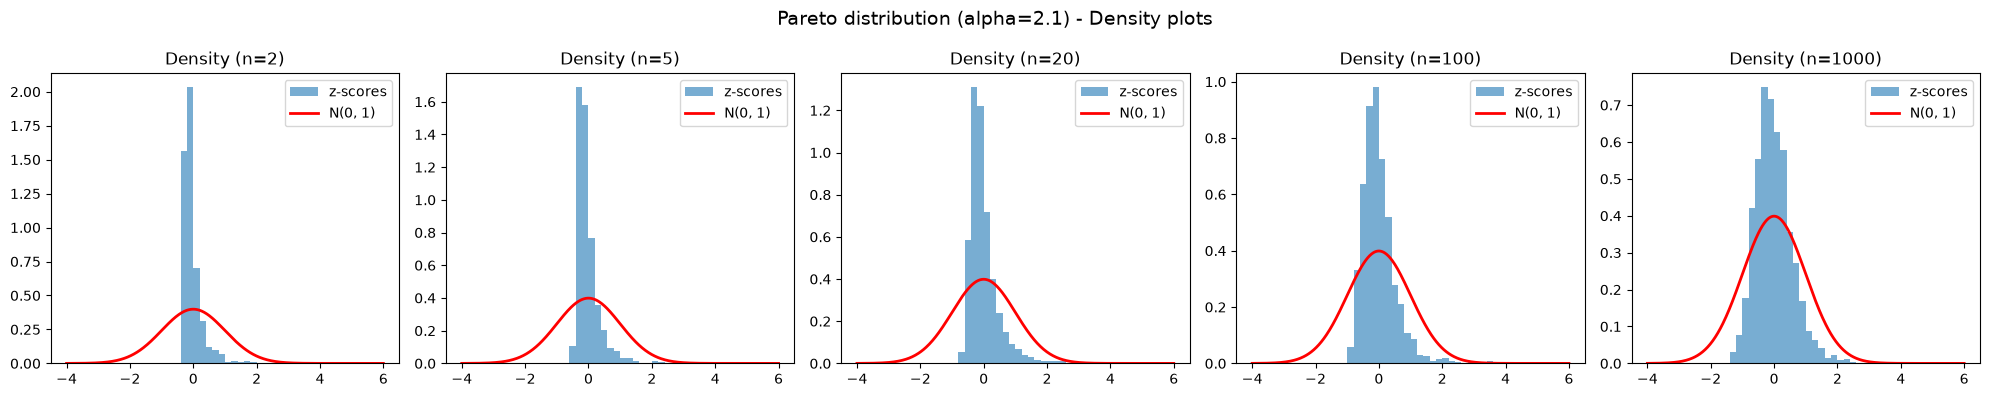

n	Mean	Variance	Skewness	Kurtosis
2	-0.016	0.179		7.018		93.682
5	-0.019	0.167		3.786		24.610
20	0.012	0.341		5.659		69.610
100	0.022	0.561		11.520		279.929
1000	0.010	0.408		2.254		18.436


In [ ]:
########## YOUR SOLUTION HERE ##########

# set the shape parameter for the Pareto distribution
alpha = 2.1

# Compute the mean and variance of the Pareto distribution
pareto_mean = alpha / (alpha - 1)
pareto_var = alpha / ((alpha - 1)**2 * (alpha - 2))

# Simulate sample means for the Pareto distribution (alpha=2.1)
pareto_sample_means = simulate_sample_means(
    sampler=lambda n: rng.pareto(alpha, size=n) + 1,
    sample_sizes=sample_sizes,
    monte_carlo_sims=2000,
)

# Compute z-scores for the Pareto distribution
pareto_z = z_scores(
    pareto_sample_means,
    mean=pareto_mean,
    var=pareto_var,
)

plot_results(pareto_z, "Pareto distribution (alpha=2.1)")
print_moments(pareto_z)

### Interpretation

The Pareto plots show strong right-skewness and extreme values, even at n = 1000. The histograms do not yet closely match the standard normal curve, and the QQ-plots show clear deviations in the right tail.

The measured variance is below 1 because rare extreme values are not sufficiently captured by the simulation. The central limit theorem applies, but convergence is much slower than for the exponential distribution.

#### 1b) Interpretation (1 pt)

Compare the convergence for the two distributions: for which sample sizes is the normal approximation reasonable? Which distribution converges faster, and why? What does this imply in practice when you rely on the CLT (e.g. for confidence intervals of a mean)?

########## YOUR SOLUTION HERE ##########

### Interpretation

The exponential distribution approaches a normal distribution relatively quickly. For n = 2 and 5, the standardized sample means are still clearly right-skewed. At n = 20, the normal approximation is reasonable in the center, while deviations remain in the tails. For n = 100 and 1000, the approximation is good.

The Pareto distribution with α = 2.1 converges much more slowly. The plots show strong right-skewness and extreme values, even at n = 1000. Therefore, the normal approximation remains poor, especially in the right tail.

The exponential distribution converges faster because large observations are much less likely. The Pareto distribution has a heavy right tail, so individual extreme observations can strongly affect the sample mean. Its variance is finite, so the CLT applies, but this does not guarantee a good approximation for a particular finite sample size.

In practice, there is no universal sample size that guarantees a reliable normal approximation. For heavy-tailed data, normal-based confidence intervals for the mean may have coverage substantially different from the intended level, even with hundreds or thousands of observations.

## Estimation theory

### Exercise 2: Bias, variance and mean squared error (4 pts)

Recall the bias–variance decomposition $\mathrm{mse}(\hat w) = \mathrm{var}(\hat w) + b^2(\hat w)$ (slide 17, derivations Section 2.1). In this exercise, $z_1, \dots, z_l \overset{\text{i.i.d.}}{\sim} \mathcal N(\mu, \sigma^2)$.

#### 2a) Optimal scaling of the sample mean (1 pt)

The lecture (slide 18, derivations Section 2.2) considers the scaled sample mean $\hat\mu_\gamma = \frac{\gamma}{l}\sum_{i=1}^l z_i$ and shows
\begin{equation*}
    \mathrm{mse}(\hat\mu_\gamma) = \frac{\gamma^2\sigma^2}{l} + \mu^2(\gamma - 1)^2 .
\end{equation*}
(The lecture calls the scaling factor $\lambda$; we write $\gamma$ to avoid a clash with the rate $\lambda$ of the exponential distribution used later.)

1. Determine the factor $\gamma^\ast$ that minimizes the mse and show that $\mathrm{mse}(\hat\mu_{\gamma^\ast}) < \mathrm{mse}(\hat\mu_1) = \sigma^2/l$, i.e. the biased estimator $\hat\mu_{\gamma^\ast}$ beats the unbiased and efficient (slide 30) sample mean $\hat\mu_1 = \hat\mu$.
2. Why is $\hat\mu_{\gamma^\ast}$ nevertheless not a usable estimator? What happens to $\gamma^\ast$ as $l \to \infty$?

########## YOUR SOLUTION HERE ##########

### Calculation

Given is

$$
\operatorname{MSE}(\hat\mu_\gamma)
=
\frac{\gamma^2\sigma^2}{l}
+
\mu^2(\gamma-1)^2.
$$

Then derive for $\gamma$ :

$$
\frac{d}{d\gamma}\operatorname{MSE}
=
2\gamma\frac{\sigma^2}{l}
+
2\mu^2(\gamma-1).
$$

For a minimum you have to set the derivative to zero:

$$
\gamma\frac{\sigma^2}{l}
+
\gamma\mu^2-\mu^2=0.
$$

Therefore,

$$
\gamma\left(\mu^2+\frac{\sigma^2}{l}\right)=\mu^2
$$

hence

$$
\boxed{
\gamma^\ast
=
\frac{\mu^2}{\mu^2+\sigma^2/l}
=
\frac{l\mu^2}{l\mu^2+\sigma^2}
}.
$$

For $\sigma^2>0$ the 2nd derivative is positive:

$$
\frac{d^2}{d\gamma^2}\operatorname{MSE}
=
2\frac{\sigma^2}{l}+2\mu^2>0.
$$

This is therefore a definite minimum.

### Question Answer

The optimal factor $\gamma^\ast$ depends on the unknown mean $\mu$, so it cannot be calculated directly. As $l \to \infty$, $\gamma^\ast \to 1$ for $\mu \neq 0$, so the estimator approaches the ordinary sample mean. If $\mu = 0$, $\gamma^\ast = 0$ for all $l$.

#### 2b) Shrinking the variance estimator (2 pts)

Let $\hat\mu = \frac1l\sum_i z_i$ and $S = \sum_{i=1}^l (z_i - \hat\mu)^2$. From the lecture you know
\begin{equation*}
    \mathbb E[S] = (l-1)\,\sigma^2 \qquad\text{(slide 23, derivations Section 2.3)}
\end{equation*}
and, for Gaussian data,
\begin{equation*}
    \mathrm{var}(S) = 2(l-1)\,\sigma^4 ,
\end{equation*}
which is the statement $\mathrm{var}(\bar\sigma^2) = \frac{2\sigma^4}{l-1}$ of slide 31 for the unbiased estimator $\bar\sigma^2 = \frac{S}{l-1}$ (slide 31 writes $\hat\sigma^2$ for this estimator; we follow the derivations note and write $\bar\sigma^2$ to distinguish it from the MLE $\hat\sigma^2_{\mathrm{MLE}} = \frac{S}{l}$ of slide 36). Consider the family of estimators
\begin{equation*}
    \hat\sigma^2_c = c\, S, \qquad c > 0,
\end{equation*}
which contains the maximum likelihood estimator $\hat\sigma^2_{\mathrm{MLE}}$ ($c = 1/l$, slide 36) and the unbiased estimator $\bar\sigma^2$ ($c = 1/(l-1)$).

1. Compute $b(\hat\sigma^2_c)$, $\mathrm{var}(\hat\sigma^2_c)$ and $\mathrm{mse}(\hat\sigma^2_c)$ as functions of $c$.
2. Determine the value $c^\ast$ that minimizes the mse.
3. Compare variance and mse of the three estimators with $c \in \{1/l,\ 1/(l-1),\ c^\ast\}$ with the Cramér–Rao bound $2\sigma^4/l$ for unbiased estimators of $\sigma^2$ (slide 31) — in general and numerically for $l = 10$, $\sigma^2 = 1$. Which estimators have a variance below the bound, and why is this not a contradiction?

########## YOUR SOLUTION HERE ##########

### Calculation

We assume $l>1$ and take a look at

$$
\hat\sigma_c^2=cS.
$$

#### Step 1: Bias

Out of

$$
\mathbb E[S]=(l-1)\sigma^2
$$

follows

$$
\mathbb E[\hat\sigma_c^2]
=
c(l-1)\sigma^2.
$$

Hence the bias is

$$
\boxed{
b(\hat\sigma_c^2)
=
\big(c(l-1)-1\big)\sigma^2
}.
$$

#### Step 2: Variance

A constant scaling is stated by

$$
\operatorname{Var}(cS)=c^2\operatorname{Var}(S).
$$

Therefore we get

$$
\boxed{
\operatorname{Var}(\hat\sigma_c^2)
=
2c^2(l-1)\sigma^4
}.
$$

Here $\sigma^4=(\sigma^2)^2$ is declared as the square of the true variance.

#### Step 3: MSE

With the bias-variance-factorisation follows

$$
\boxed{
\operatorname{MSE}(\hat\sigma_c^2)
=
\sigma^4
\left[
2c^2(l-1)
+
\big(c(l-1)-1\big)^2
\right]
}.
$$

Multiplying that produces

$$
\operatorname{MSE}(\hat\sigma_c^2)
=
\sigma^4
\left[
(l-1)(l+1)c^2-2(l-1)c+1
\right].
$$

#### Step 4: Define optimal factore

Derive for $c$ :

$$
\frac{d}{dc}\operatorname{MSE}
=
2\sigma^4(l-1)\big((l+1)c-1\big).
$$

The derivative is zero for

$$
\boxed{
c^\ast=\frac1{l+1}
}.
$$

The second derivative is positive:

$$
\frac{d^2}{dc^2}\operatorname{MSE}
=
2\sigma^4(l-1)(l+1)>0.
$$

The MSE-optimal estimator within the looked upon family is stated as

$$
\boxed{
\hat\sigma_{\mathrm{opt}}^2
=
\frac{S}{l+1}
}.
$$


Compared to the optimale factor of 2a is $c^\ast$ depending only on the sample size. This estimator is directly applicable.

#### Step 5: Comparison

| Estimator | Factor $c$ | Bias | Variance | MSE |
|---|---|---|---|---|
| MLE | $\frac1l$ | $-\frac{\sigma^2}{l}$ | $\frac{2(l-1)}{l^2}\sigma^4$ | $\frac{2l-1}{l^2}\sigma^4$ |
| Unbiased | $\frac1{l-1}$ | $0$ | $\frac{2}{l-1}\sigma^4$ | $\frac{2}{l-1}\sigma^4$ |
| MSE-optimal | $\frac1{l+1}$ | $-\frac{2\sigma^2}{l+1}$ | $\frac{2(l-1)}{(l+1)^2}\sigma^4$ | $\frac{2}{l+1}\sigma^4$ |

The stated Cramér–Rao-Schranke for unbiased estimators is

$$
\operatorname{CRLB}=\frac{2\sigma^4}{l}.
$$

Variances obey:

$$
\boxed{
\operatorname{Var}(\hat\sigma_{\mathrm{opt}}^2)
<
\operatorname{Var}(\hat\sigma_{\mathrm{MLE}}^2)
<
\operatorname{CRLB}
<
\operatorname{Var}(\bar\sigma^2)
}.
$$

MSEs also obey:

$$
\boxed{
\operatorname{MSE}(\hat\sigma_{\mathrm{opt}}^2)
<
\operatorname{MSE}(\hat\sigma_{\mathrm{MLE}}^2)
<
\operatorname{CRLB}
<
\operatorname{MSE}(\bar\sigma^2)
}.
$$

Therefore, the unbiased estimator never reaches the stated bound given a finite $l$.

#### Step 6: Numerical comparison bt.  $l=10$ and $\sigma^2=1$

| Estimator | Bias | Variance | MSE |
|---|---:|---:|---:|
| MLE | −0.1000 | 0.1800 | 0.1900 |
| Unbiased | 0.0000 | 0.2222 | 0.2222 |
| MSE-optimal | −0.1818 | 0.1488 | 0.1818 |

For all $l>1$, both variance and MSE follow the ordering

$$
\text{MSE-optimal}<\text{MLE}<\text{CRLB}<\text{unbiased}.
$$

This is no contradiction: the stated CRLB applies only to unbiased estimators. The two biased estimators reduce variance enough to achieve a smaller MSE.

#### 2c) Simulation (1 pt)

Write a Python routine that estimates bias, variance and mse of the three estimators of 2b ($c \in \{1/l,\ 1/(l-1),\ 1/(l+1)\}$) from $l = 10$ standard normally distributed samples ($\sigma^2 = 1$) using $10\,000$ independent trials. Compare with the theoretical values of 2b and with the CRLB, and interpret the result.

*Hint: `np.var(z, axis=1, ddof=k)` computes $\frac{1}{l-k}\sum_i (z_i - \hat\mu)^2$ for each row of `z`.*

In [ ]:
########## YOUR SOLUTION HERE ##########

# Set the random seed for reproducibility
rng_ex2 = np.random.default_rng(0)

# Set the sample size, number of trials, and true parameters for the normal distribution
n = 10
trials = 10_000
true_mean = 0.0
true_var = 1.0

# Generate 10,000 samples of size n from the normal distribution
z = rng_ex2.normal(
    loc=true_mean,
    scale=np.sqrt(true_var),
    size=(trials, n),
)

# Compute the sample means and sum of squared deviations from the sample means
sample_means = np.mean(z, axis=1, keepdims=True)
S = np.sum((z - sample_means)**2, axis=1)

# Compute the sample variance estimators for MLE, unbiased, and MSE-optimal
factors = {
    "MLE": 1 / n,
    "Unbiased": 1 / (n - 1),
    "MSE-optimal": 1 / (n + 1),
}

# Compute the Cramer-Rao lower bound (CRLB) for unbiased estimators of the variance
crlb = 2 * true_var**2 / n

# Print the CRLB for unbiased estimators
print(f"CRLB for unbiased estimators: {crlb:.6f}\n")

# Print the header for the results table
print(
    f"{'Estimator':<14}"
    f"{'Bias emp.':>12}"
    f"{'Bias theory':>14}"
    f"{'Var emp.':>12}"
    f"{'Var theory':>14}"
    f"{'MSE emp.':>12}"
    f"{'MSE theory':>14}"
)

# Loop over the estimators and compute empirical and theoretical quantities
for name, c in factors.items():

    # Compute the sample variance estimates for the current estimator
    estimates = c * S

    # Empirical quantities across the 10,000 trials.
    empirical_bias = np.mean(estimates) - true_var
    empirical_var = np.var(estimates, ddof=0)
    empirical_mse = np.mean((estimates - true_var)**2)

    # Theoretical quantities from Exercise 2b.
    theoretical_bias = (c * (n - 1) - 1) * true_var
    theoretical_var = 2 * c**2 * (n - 1) * true_var**2
    theoretical_mse = theoretical_var + theoretical_bias**2

    # Print the results for the current estimator
    print(
        f"{name:<14}"
        f"{empirical_bias:>12.6f}"
        f"{theoretical_bias:>14.6f}"
        f"{empirical_var:>12.6f}"
        f"{theoretical_var:>14.6f}"
        f"{empirical_mse:>12.6f}"
        f"{theoretical_mse:>14.6f}"
    )

CRLB for unbiased estimators: 0.200000

Estimator        Bias emp.   Bias theory    Var emp.    Var theory    MSE emp.    MSE theory
MLE              -0.099643     -0.100000    0.180864      0.180000    0.190793      0.190000
Unbiased          0.000397      0.000000    0.223289      0.222222    0.223289      0.222222
MSE-optimal      -0.181493     -0.181818    0.149475      0.148760    0.182414      0.181818


########## YOUR SOLUTION HERE ##########

### Interpretation

The simulation results closely match the theoretical values. Small differences are due to the finite number of trials.

The unbiased estimator has almost zero bias (0.0004), but the largest MSE (0.2233). The MLE has a negative bias (−0.0996), but a lower MSE (0.1908). The MSE-optimal estimator has a larger negative bias (−0.1815), yet achieves the lowest MSE (0.1824) because of its smaller variance.

Both biased estimators have variances below the CRLB of 0.2. This is no contradiction, since the stated bound applies only to unbiased estimators. These results illustrate that accepting some bias can reduce the overall estimation error.

Translated with DeepL.com (free version)

### Exercise 3: Fisher information and the Cramér–Rao bound (4 pts)

For a model $p(z; w)$ with scalar parameter $w$, the score and the Fisher information of a single observation are (slide 27)
\begin{equation*}
    s(z; w) = \frac{\partial \log p(z; w)}{\partial w}, \qquad I_F(w) = \mathbb E_{z \sim p(\cdot\,; w)}\big[s(z; w)^2\big],
\end{equation*}
and under the regularity conditions of the lecture (slide 28, derivations Section 2.4)
\begin{equation*}
    \mathbb E_{z \sim p(\cdot\,; w)}\big[s(z; w)\big] = 0 \qquad\text{and}\qquad I_F(w) = -\mathbb E_{z \sim p(\cdot\,; w)}\Big[\frac{\partial^2 \log p(z; w)}{\partial w^2}\Big].
\end{equation*}
You may assume that all regularity conditions hold for the distributions in this exercise.

#### 3a) Fisher information of an i.i.d. sample (1 pt)

Let $\mathbf Z = (z_1, \dots, z_l)$ be i.i.d. samples from $p(z; w)$ with likelihood $\mathcal L(\mathbf Z; w) = \prod_{i=1}^l p(z_i; w)$, and assume that the Fisher information $I_F(w)$ of a single observation is known. Show that the Fisher information of the whole sample,
\begin{equation*}
    I_F^{(l)}(w) := -\mathbb E_{\mathbf Z \sim p(\cdot\,; w)^l}\Big[\frac{\partial^2}{\partial w^2} \log \mathcal L(\mathbf Z; w)\Big],
\end{equation*}
equals $l \cdot I_F(w)$. Interpret the result and relate it to slides 30 and 31, where $I_F(\mu) = l/\sigma^2$ and $I_F(\sigma^2) = l/(2\sigma^4)$ denote the information of the whole sample.

########## YOUR SOLUTION HERE ##########

### Calculation

Because the observations are independent, the likelihood is

$$
\mathcal L(\mathbf Z;w)=\prod_{i=1}^l p(z_i;w).
$$

Taking logarithms gives

$$
\log\mathcal L(\mathbf Z;w)
=\sum_{i=1}^l\log p(z_i;w).
$$

Therefore,

$$
I_F^{(l)}(w)
=
-\mathbb E\left[
\sum_{i=1}^l
\frac{\partial^2}{\partial w^2}\log p(z_i;w)
\right]
=
\sum_{i=1}^l I_F(w).
$$

Thus,

$$
\boxed{I_F^{(l)}(w)=lI_F(w)}.
$$

Each independent observation contributes the same amount of information, so the total information grows linearly with the sample size.

For normally distributed observations, the single-observation information is

$$
I_F(\mu)=\frac1{\sigma^2},
\qquad
I_F(\sigma^2)=\frac1{2\sigma^4}.
$$

Multiplying by $l$ gives

$$
I_F^{(l)}(\mu)=\frac l{\sigma^2},
\qquad
I_F^{(l)}(\sigma^2)=\frac l{2\sigma^4}.
$$


#### 3b) Exponential distribution: Fisher information and CRLB (1 pt)

Consider an exponentially distributed random variable $z$ with probability density function (pdf)
\begin{equation*}
    p(z; \lambda) = \lambda e^{-\lambda z}, \qquad z \ge 0,
\end{equation*}
where $\lambda > 0$ is the rate parameter; recall $\mathbb E[z] = 1/\lambda$ and $\mathrm{var}(z) = 1/\lambda^2$.

1. Compute the Fisher information $I_F(\lambda)$ of one observation using the second-derivative form, and verify the result with the definition $I_F(\lambda) = \mathbb E\big[s(z; \lambda)^2\big]$.
2. State the Cramér–Rao lower bound for unbiased estimators of $\lambda$ based on $l$ i.i.d. observations.

########## YOUR SOLUTION HERE ##########

### Calculation

For one observation,

$$
\log p(z;\lambda)=\log\lambda-\lambda z.
$$

The score and second derivative are

$$
s(z;\lambda)=\frac1\lambda-z,
\qquad
\frac{\partial^2}{\partial\lambda^2}\log p(z;\lambda)
=-\frac1{\lambda^2}.
$$

Hence,

$$
\boxed{
I_F(\lambda)
=
-\mathbb E\left[-\frac1{\lambda^2}\right]
=
\frac1{\lambda^2}
}.
$$

To verify this using the squared score, note that
$\mathbb E[z]=1/\lambda$. Therefore,

$$
\mathbb E[s(z;\lambda)^2]
=
\mathbb E\left[\left(z-\frac1\lambda\right)^2\right]
=
\operatorname{Var}(z)
=
\frac1{\lambda^2}.
$$

For $l$ independent observations,

$$
I_F^{(l)}(\lambda)=\frac l{\lambda^2}.
$$

Thus, every unbiased estimator of $\lambda$ satisfies

$$
\boxed{
\operatorname{Var}(\hat\lambda)\geq\frac{\lambda^2}{l}
}.
$$

#### 3c) Reparametrization: the mean of the exponential distribution (2 pts)

Instead of the rate $\lambda$, the exponential distribution can be parametrized by its mean $\theta = 1/\lambda$:
\begin{equation*}
    p(z; \theta) = \frac1\theta\, e^{-z/\theta}, \qquad z \ge 0,\ \theta > 0 .
\end{equation*}

1. Compute the Fisher information $I_F(\theta)$ of one observation.
2. Show for a general model with scalar parameter: if $w = g(\theta)$ with $g$ differentiable and invertible, then $I_F(\theta) = I_F(w)\,\big(g'(\theta)\big)^2$, where $I_F(w)$ denotes the Fisher information in the parametrization $w$. Use this to re-derive $I_F(\theta)$ from $I_F(\lambda)$ of 3b.
3. State the CRLB for unbiased estimators of $\theta$ based on $l$ observations. Show that the sample mean $\hat\mu = \frac1l\sum_i z_i$ is an unbiased estimator of $\theta$ that attains the bound, i.e. is efficient. Is the corresponding estimator $1/\hat\mu$ of the rate $\lambda$ also unbiased and efficient? (Answer qualitatively; Exercise 4 quantifies this.)

########## YOUR SOLUTION HERE ##########

### Caluclation

#### 1. Fisher information for theta

With $\theta=1/\lambda$,

$$
\log p(z;\theta)=-\log\theta-\frac z\theta.
$$

Therefore,

$$
s(z;\theta)=-\frac1\theta+\frac z{\theta^2},
$$

$$
\frac{\partial^2}{\partial\theta^2}\log p(z;\theta)
=
\frac1{\theta^2}-\frac{2z}{\theta^3}.
$$

Using $\mathbb E[z]=\theta$ gives

$$
\boxed{
I_F(\theta)
=
-\left(\frac1{\theta^2}-\frac{2\theta}{\theta^3}\right)
=
\frac1{\theta^2}
}.
$$

#### 2. General transformation rule

If $w=g(\theta)$, the chain rule gives

$$
s_\theta(z;\theta)
=
\frac{\partial}{\partial\theta}\log p(z;g(\theta))
=
s_w(z;g(\theta))g'(\theta).
$$

Squaring and taking expectations yields

$$
\boxed{
I_{F,\theta}(\theta)
=
I_{F,w}(g(\theta))[g'(\theta)]^2
}.
$$

For $\lambda=g(\theta)=1/\theta$,

$$
g'(\theta)=-\frac1{\theta^2}.
$$

Consequently,

$$
I_F(\theta)
=
\frac1{\lambda^2}\frac1{\theta^4}
=
\theta^2\frac1{\theta^4}
=
\frac1{\theta^2},
$$

which confirms the direct calculation.

#### 3. CRLB and efficiency

For $l$ observations, the CRLB for unbiased estimators of $\theta$ is

$$
\boxed{
\operatorname{Var}(\hat\theta)\geq\frac{\theta^2}{l}
}.
$$

The sample mean satisfies

$$
\mathbb E[\hat\mu]=\theta,
\qquad
\operatorname{Var}(\hat\mu)=\frac{\theta^2}{l}.
$$

It is therefore unbiased and attains the CRLB:

$$
\boxed{\hat\mu\text{ is efficient for estimating }\theta.}
$$

However, its reciprocal $1/\hat\mu$ is not unbiased for $\lambda$.
Because $1/x$ is strictly convex for $x>0$, Jensen's inequality gives

$$
\mathbb E\left[\frac1{\hat\mu}\right]
>
\frac1{\mathbb E[\hat\mu]}
=
\lambda
$$

whenever the expectation is finite. For $l=1$, this expectation is infinite.

Thus, taking the reciprocal does not preserve unbiasedness or finite-sample efficiency. The rate estimator is nevertheless asymptotically efficient, as investigated in Exercise 4.

### Exercise 4: Maximum likelihood estimation (3 pts)

#### 4a) MLE of the rate (1 pt)

Let $z_1, \dots, z_l$ be i.i.d. exponentially distributed with rate $\lambda$ (as in 3b). Derive the maximum likelihood estimator $\hat\lambda_{\mathrm{MLE}}$ from the log-likelihood and verify that it is a maximum. What is the maximum likelihood estimator $\hat\theta_{\mathrm{MLE}}$ of the mean $\theta = 1/\lambda$ (parametrization of 3c)?

*Hint: $\theta \mapsto \lambda = 1/\theta$ is a bijection of $(0, \infty)$ onto itself — what does this mean for the $\arg\max$?*

########## YOUR SOLUTION HERE ##########

### Calculation

Let $T=\sum_{i=1}^l z_i$. The likelihood is

$$
\mathcal L(\mathbf Z;\lambda)
=
\lambda^l e^{-\lambda T}.
$$

The log-likelihood is

$$
\ell(\lambda)=l\log\lambda-\lambda T.
$$

Differentiating gives

$$
\ell'(\lambda)=\frac l\lambda-T.
$$

Setting this equal to zero yields

$$
\boxed{
\hat\lambda_{\mathrm{MLE}}
=
\frac lT
=
\frac1{\hat\mu}
}.
$$

Since

$$
\ell''(\lambda)=-\frac l{\lambda^2}<0,
$$

the log-likelihood is strictly concave, so the stationary point is the unique global maximum for $T>0$, which holds almost surely.

The transformation $\theta=1/\lambda$ is bijective. Maximizing over $\theta$ therefore selects the same distribution as maximizing over $\lambda$. Hence,

$$
\boxed{
\hat\theta_{\mathrm{MLE}}
=
\frac1{\hat\lambda_{\mathrm{MLE}}}
=
\frac Tl
=
\hat\mu
}.
$$

#### 4b) Finite-sample behaviour of the MLE (2 pts)

Simulate the estimator $\hat\lambda_{\mathrm{MLE}} = 1/\hat\mu$ for $\lambda = 2$ and the sample sizes $l \in \{5, 10, 50, 500\}$ using $10\,000$ independent trials each. For every $l$, report bias, variance and mse of $\hat\lambda_{\mathrm{MLE}}$, compare the variance with the CRLB $\lambda^2/l$ of 3b, and report also $l \cdot \mathrm{var}(\hat\lambda_{\mathrm{MLE}})$. Do the same for the bias-corrected estimator
\begin{equation*}
    \tilde\lambda = \frac{l-1}{l}\,\hat\lambda_{\mathrm{MLE}} = \frac{l-1}{\sum_{i=1}^l z_i} .
\end{equation*}
Interpret your results in the light of slide 37 (consistency, asymptotic unbiasedness, asymptotic efficiency): Is $\hat\lambda_{\mathrm{MLE}}$ unbiased? Efficient? Is $\tilde\lambda$? Compare with the findings of Exercise 2 about bias correction.

In [7]:
########## YOUR SOLUTION HERE ##########

# Set the random seed for reproducibility
rng_ex4 = np.random.default_rng(0)

# Set the true rate parameter for the exponential distribution
true_rate = 2.0
sample_sizes_ex4 = [5, 10, 50, 500]
trials_ex4 = 10_000

# Store the simulated sums for reuse in Exercise 5c.
sums_ex4 = {}

# Print the header for the results table
print(
    f"{'n':>5} {'Estimator':<12} {'Source':<8}"
    f"{'Bias':>11} {'Variance':>12} {'MSE':>12}"
    f"{'CRLB':>11} {'n * Var':>12}"
)

# Loop over the sample sizes and compute empirical and theoretical quantities for each estimator
for n in sample_sizes_ex4:

    # Generate 10,000 samples of size n from the exponential distribution with the true rate parameter
    samples = rng_ex4.exponential(
        scale=1 / true_rate,
        size=(trials_ex4, n),
    )

    # Compute the sum of the samples for each trial and store it in the dictionary for reuse
    T = np.sum(samples, axis=1)
    sums_ex4[n] = T

    # Compute the sample variance estimates for the MLE and corrected estimators
    estimates = {
        "MLE": n / T,
        "Corrected": (n - 1) / T,
    }

    # Compute the Cramer-Rao lower bound (CRLB) for unbiased estimators of the rate parameter
    crlb = true_rate**2 / n

    # Compute the theoretical bias, variance, and MSE for each estimator
    theoretical_values = {
        "MLE": (
            true_rate / (n - 1),
            true_rate**2 * n**2 / ((n - 1)**2 * (n - 2)),
            true_rate**2 * (n + 2) / ((n - 1) * (n - 2)),
        ),
        "Corrected": (
            0.0,
            true_rate**2 / (n - 2),
            true_rate**2 / (n - 2),
        ),
    }

    # Print the results for each estimator and source (empirical and theoretical)
    for name, values in estimates.items():
        empirical_bias = np.mean(values) - true_rate
        empirical_var = np.var(values, ddof=0)
        empirical_mse = np.mean((values - true_rate)**2)

        rows = [
            ("Emp.", empirical_bias, empirical_var, empirical_mse),
            ("Theory", *theoretical_values[name]),
        ]

        for source, bias, variance, mse in rows:
            print(
                f"{n:>5} {name:<12} {source:<8}"
                f"{bias:>11.6f} {variance:>12.6f} {mse:>12.6f}"
                f"{crlb:>11.6f} {n * variance:>12.6f}"
            )

    print()

    n Estimator    Source         Bias     Variance          MSE       CRLB      n * Var
    5 MLE          Emp.       0.503012     2.075456     2.328477   0.800000    10.377280
    5 MLE          Theory     0.500000     2.083333     2.333333   0.800000    10.416667
    5 Corrected    Emp.       0.002410     1.328292     1.328298   0.800000     6.641459
    5 Corrected    Theory     0.000000     1.333333     1.333333   0.800000     6.666667

   10 MLE          Emp.       0.236308     0.637904     0.693745   0.400000     6.379038
   10 MLE          Theory     0.222222     0.617284     0.666667   0.400000     6.172840
   10 Corrected    Emp.       0.012677     0.516702     0.516863   0.400000     5.167021
   10 Corrected    Theory     0.000000     0.500000     0.500000   0.400000     5.000000

   50 MLE          Emp.       0.040121     0.085742     0.087352   0.080000     4.287098
   50 MLE          Theory     0.040816     0.086769     0.088435   0.080000     4.338470
   50 Corrected    

########## YOUR SOLUTION HERE ##########

### Calculation

The sum $T=\sum_i z_i$ follows a Gamma distribution with shape $l$ and rate $\lambda$. Its inverse moments are

$$
\mathbb E[T^{-1}]=\frac{\lambda}{l-1},
\qquad
\mathbb E[T^{-2}]
=
\frac{\lambda^2}{(l-1)(l-2)},
$$

for $l>1$ and $l>2$, respectively.

For the sample sizes considered here, all required moments exist.

#### MLE

For $\hat\lambda_{\mathrm{MLE}}=l/T$,

$$
\mathbb E[\hat\lambda_{\mathrm{MLE}}]
=
\frac{l\lambda}{l-1}.
$$

Therefore,

$$
\boxed{
b(\hat\lambda_{\mathrm{MLE}})
=
\frac{\lambda}{l-1}
},
$$

$$
\boxed{
\operatorname{Var}(\hat\lambda_{\mathrm{MLE}})
=
\frac{\lambda^2l^2}{(l-1)^2(l-2)}
},
$$

$$
\boxed{
\operatorname{MSE}(\hat\lambda_{\mathrm{MLE}})
=
\frac{\lambda^2(l+2)}{(l-1)(l-2)}
}.
$$

The MLE overestimates the rate on average. Its variance is above the CRLB $\lambda^2/l$ for finite $l>2$.

#### Bias-corrected estimator

For $\tilde\lambda=(l-1)/T$,

$$
\mathbb E[\tilde\lambda]=\lambda.
$$

Thus,

$$
\boxed{b(\tilde\lambda)=0},
$$

$$
\boxed{
\operatorname{Var}(\tilde\lambda)
=
\operatorname{MSE}(\tilde\lambda)
=
\frac{\lambda^2}{l-2}
}.
$$

This estimator is unbiased but not finite-sample efficient, because

$$
\frac{\lambda^2}{l-2}>\frac{\lambda^2}{l}.
$$

#### Asymptotic behaviour

By the law of large numbers,

$$
\hat\mu\longrightarrow\frac1\lambda,
$$

so both estimators converge to $\lambda$ and are consistent.

The bias of the MLE approaches zero. Furthermore,

$$
l\operatorname{Var}(\hat\lambda_{\mathrm{MLE}})
=
\lambda^2\frac{l^3}{(l-1)^2(l-2)}
\longrightarrow\lambda^2,
$$

and

$$
l\operatorname{Var}(\tilde\lambda)
=
\lambda^2\frac l{l-2}
\longrightarrow\lambda^2.
$$

Both estimators are asymptotically efficient. For $\lambda=2$, the limiting value of $l\operatorname{Var}$ is $4$.

#### Interpretation and comparison with Exercise 2

The simulation should approximately reproduce these theoretical values, with small Monte Carlo differences.

- The MLE has positive bias and is not finite-sample efficient in the unbiased-CRLB sense.
- The corrected estimator is unbiased, but its variance remains above the CRLB.
- Both become more accurate as the sample size increases.
- Both are consistent and asymptotically efficient.

Here, bias correction reduces both variance and MSE:

$$
\operatorname{MSE}(\hat\lambda_{\mathrm{MLE}})
-
\operatorname{MSE}(\tilde\lambda)
=
\frac{3\lambda^2}{(l-1)(l-2)}>0.
$$

In Exercise 2, correcting the variance estimator's bias increased its variance and MSE. Thus, removing bias does not automatically improve or worsen an estimator: the result depends on the complete bias–variance trade-off.

## Bayesian estimation

### Exercise 5: A conjugate prior for the exponential rate (3 pts)

In Bayesian estimation the parameter is treated as a random variable with a *prior* density $p(\lambda)$, and the likelihood is read as the conditional density of the data given the parameter, $p(\mathbf Z \mid \lambda) = \mathcal L(\mathbf Z; \lambda)$. Bayes' theorem combines both into the *posterior*
\begin{equation*}
    p(\lambda \mid \mathbf Z) = \frac{p(\mathbf Z \mid \lambda)\, p(\lambda)}{p(\mathbf Z)} \;\propto\; p(\mathbf Z \mid \lambda)\, p(\lambda),
\end{equation*}
where the *evidence* $p(\mathbf Z) = \int p(\mathbf Z \mid \lambda)\, p(\lambda)\, \mathrm d\lambda$ does not depend on $\lambda$. ($f(\lambda) \propto g(\lambda)$ means $f(\lambda) = C\, g(\lambda)$ for a constant $C > 0$ that does not depend on $\lambda$.) Point estimates derived from the posterior are the *posterior mean* $\mathbb E[\lambda \mid \mathbf Z]$ and the *maximum a posteriori* (MAP) estimator $\hat\lambda_{\mathrm{MAP}} \in \arg\max_\lambda p(\lambda \mid \mathbf Z)$. A prior is called *conjugate* to a likelihood if the posterior belongs to the same family of distributions as the prior (see derivations Section 2.6 for the Gamma–Poisson model, and lecture II.2).

The Gamma distribution $\mathrm{Gamma}(\alpha, \beta)$ with shape $\alpha > 0$ and rate $\beta > 0$ has the density
\begin{equation*}
    p(\lambda) = \frac{\beta^\alpha}{\Gamma(\alpha)}\, \lambda^{\alpha - 1} e^{-\beta\lambda}, \qquad \lambda > 0,
\end{equation*}
with mean $\alpha/\beta$, variance $\alpha/\beta^2$ and mode $(\alpha - 1)/\beta$ for $\alpha \ge 1$.

As before, the data are $z_1, \dots, z_l \mid \lambda \overset{\text{i.i.d.}}{\sim} p(z \mid \lambda) = \lambda e^{-\lambda z}$, $z \ge 0$.

#### 5a) Posterior (1 pt)

Assume the prior $\lambda \sim \mathrm{Gamma}(\alpha, \beta)$. Show that the posterior is again a Gamma distribution,
\begin{equation*}
    \lambda \mid \mathbf Z \sim \mathrm{Gamma}\Big(\alpha + l,\ \beta + \sum_{i=1}^l z_i\Big),
\end{equation*}
i.e. the Gamma prior is conjugate to the exponential likelihood. Work with $\propto$ and keep only the factors that depend on $\lambda$.

########## YOUR SOLUTION HERE ##########

### Calculation

Let $T=\sum_{i=1}^l z_i$. The likelihood, keeping only factors depending on $\lambda$, is

$$
p(\mathbf Z\mid\lambda)
\propto
\lambda^l e^{-\lambda T}.
$$

The Gamma prior is

$$
p(\lambda)
\propto
\lambda^{\alpha-1}e^{-\beta\lambda}.
$$

By Bayes' theorem,

$$
p(\lambda\mid\mathbf Z)
\propto
p(\mathbf Z\mid\lambda)p(\lambda).
$$

Therefore,

$$
p(\lambda\mid\mathbf Z)
\propto
\lambda^{\alpha+l-1}
e^{-(\beta+T)\lambda}.
$$

This is the kernel of a Gamma distribution with shape $\alpha+l$ and rate $\beta+T$. Hence,

$$
\boxed{
\lambda\mid\mathbf Z
\sim
\operatorname{Gamma}\left(
\alpha+l,\,
\beta+\sum_{i=1}^l z_i
\right)
}.
$$

The posterior belongs to the same family as the prior, so the Gamma prior is conjugate to the exponential likelihood.

#### 5b) Point estimates (1 pt)

1. Compute the posterior mean $\mathbb E[\lambda \mid \mathbf Z]$ and the MAP estimator $\hat\lambda_{\mathrm{MAP}}$, and compare both with $\hat\lambda_{\mathrm{MLE}} = l / \sum_i z_i$ from 4a.
2. Interpret the prior parameters $\alpha$ and $\beta$ as "pseudo-observations".
3. Show that both estimators converge to $\hat\lambda_{\mathrm{MLE}}$ as $l \to \infty$ (for fixed $\hat\mu = \frac1l\sum_i z_i$). For which choice of $(\alpha, \beta)$ does the MAP estimator coincide with the MLE for every $l$, and what does the corresponding "prior" look like?

########## YOUR SOLUTION HERE ##########

### Calculation

#### 1. Posterior mean and MAP

Using the mean and mode of the posterior Gamma distribution gives

$$
\boxed{
\mathbb E[\lambda\mid\mathbf Z]
=
\frac{\alpha+l}{\beta+T}
},
$$

$$
\boxed{
\hat\lambda_{\mathrm{MAP}}
=
\frac{\alpha+l-1}{\beta+T}
}.
$$

Since $l\geq1$ and $\alpha>0$, the posterior shape $\alpha+l$ is greater than 1, so the MAP is an interior mode.

The MLE is

$$
\hat\lambda_{\mathrm{MLE}}=\frac lT.
$$

The posterior estimates modify the MLE by adding prior contributions to the numerator and denominator.

The posterior mean can also be written as

$$
\mathbb E[\lambda\mid\mathbf Z]
=
\frac{T}{T+\beta}\hat\lambda_{\mathrm{MLE}}
+
\frac{\beta}{T+\beta}\frac{\alpha}{\beta}.
$$

It is therefore a weighted average of the MLE and the prior mean.

#### 2. Pseudo-observations

The log-likelihood is

$$
l\log\lambda-T\lambda.
$$

The log-prior, ignoring constants, is

$$
(\alpha-1)\log\lambda-\beta\lambda.
$$

Thus, in the MAP calculation, the prior acts like a contribution of $\alpha-1$ pseudo-observations with total waiting time $\beta$:

$$
l\mapsto l+\alpha-1,
\qquad
T\mapsto T+\beta.
$$

For $\alpha>1$, the corresponding pseudo-observation mean is $\beta/(\alpha-1)$.

This is a literal positive-count interpretation only when $\alpha>1$; for noninteger values it is a fractional-count analogy. The posterior mean instead uses $\alpha+l$ in its numerator because a Gamma mean and mode differ by one shape unit.

#### 3. Large-sample behaviour

For a fixed positive sample mean $\hat\mu=T/l$,

$$
\mathbb E[\lambda\mid\mathbf Z]
=
\frac{1+\alpha/l}{\hat\mu+\beta/l}
\longrightarrow
\frac1{\hat\mu}
=
\hat\lambda_{\mathrm{MLE}}.
$$

Similarly,

$$
\hat\lambda_{\mathrm{MAP}}
=
\frac{1+(\alpha-1)/l}{\hat\mu+\beta/l}
\longrightarrow
\hat\lambda_{\mathrm{MLE}}.
$$

Thus, for fixed prior parameters, the influence of the prior vanishes as the sample size increases.

For the MAP to equal the MLE for every sample size and every positive data sum, we require

$$
\frac{l+\alpha-1}{T+\beta}=\frac lT.
$$

Equivalently,

$$
(\alpha-1)T=l\beta.
$$

This holds for all such datasets only if

$$
\boxed{\alpha=1,\qquad\beta=0}.
$$

The corresponding formal prior is

$$
p(\lambda)\propto1,\qquad\lambda>0.
$$

It is a flat, improper prior: its integral over $(0,\infty)$ is infinite, so it is not a proper Gamma distribution. Nevertheless, it produces a proper posterior for $l\geq1$ and $T>0$, with MAP equal to the MLE.

#### 5c) Simulation: posterior mean versus MLE (1 pt)

Extend the simulation of 4b ($\lambda = 2$, $l \in \{5, 10, 50, 500\}$, $10\,000$ trials): compare bias, variance and mse of the posterior mean $\mathbb E[\lambda \mid \mathbf Z]$ with those of $\hat\lambda_{\mathrm{MLE}}$ for

* an *informative, correct* prior $\mathrm{Gamma}(4, 2)$ (prior mean $2 = \lambda$),
* an *informative, wrong* prior $\mathrm{Gamma}(20, 2)$ (prior mean $10$).

Interpret the results with the bias–variance decomposition.

In [8]:
########## YOUR SOLUTION HERE ##########

# Reuses true_rate and sums_ex4 from Exercise 4b.

# Define the prior distributions for the Bayesian estimators.
priors = {
    "Correct prior": (4.0, 2.0),
    "Wrong prior": (20.0, 2.0),
}

# Print the header for the results table
print(
    f"{'n':>5} {'Estimator':<16}"
    f"{'Bias':>12} {'Variance':>12}"
    f"{'Bias^2':>12} {'MSE':>12}"
)

# Loop over the sample sizes and compute empirical quantities for each estimator (MLE and Bayesian).
for n, T in sums_ex4.items():

    # Compute the sample variance estimates for the MLE and Bayesian estimators
    estimates = {
        "MLE": n / T,
    }

    # Compute the Bayesian estimates for each prior distribution
    for name, (alpha, beta) in priors.items():
        estimates[name] = (alpha + n) / (beta + T)

    # Compute the empirical bias, variance, and MSE for each estimator
    for name, values in estimates.items():
        bias = np.mean(values) - true_rate
        variance = np.var(values, ddof=0)
        mse = np.mean((values - true_rate)**2)

        print(
            f"{n:>5} {name:<16}"
            f"{bias:>12.6f} {variance:>12.6f}"
            f"{bias**2:>12.6f} {mse:>12.6f}"
        )

    print()

    n Estimator               Bias     Variance      Bias^2          MSE
    5 MLE                 0.503012     2.075456    0.253021     2.328477
    5 Correct prior       0.118919     0.253438    0.014142     0.267580
    5 Wrong prior         3.885886     1.955541   15.100107    17.055647

   10 MLE                 0.236308     0.637904    0.055841     0.693745
   10 Correct prior       0.110534     0.234808    0.012218     0.247026
   10 Wrong prior         2.522574     1.078201    6.363378     7.441579

   50 MLE                 0.040121     0.085742    0.001610     0.087352
   50 Correct prior       0.034182     0.072323    0.001168     0.073491
   50 Wrong prior         0.636902     0.121530    0.405645     0.527175

  500 MLE                 0.005578     0.008115    0.000031     0.008146
  500 Correct prior       0.005502     0.007985    0.000030     0.008015
  500 Wrong prior         0.069169     0.008500    0.004784     0.013284



########## YOUR SOLUTION HERE ##########

### Interpretation

The results confirm that the correct prior improves estimation, especially for small samples. At n = 5, it reduces the MSE from 2.3285 for the MLE to 0.2676 by reducing both bias and variance.

The wrong prior introduces a large positive bias. At n = 5, its squared bias dominates the MSE, which increases to 17.0556. It does not consistently reduce variance: for n = 10, 50 and 500, its variance is higher than that of the MLE.

As the sample size increases, the influence of both priors decreases. At n = 500, the correct prior and MLE have nearly identical MSEs, while the wrong prior still produces a higher MSE.

These results illustrate that a suitable prior can improve estimation, whereas an unsuitable prior can increase the error through bias and potentially variance.